In [6]:
! python -m pip install -U pip
! python -m pip install scikit-learn matplotlib joblib numpy

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----------------------- ---------------- 1.0/1.8 MB 4.6 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 6.7 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 25.2
    Uninstalling pip-25.2:
      Successfully uninstalled pip-25.2


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


   ---------------------------------------- 0.0/8.1 MB ? eta -:--:--
   ---------------- ----------------------- 3.4/8.1 MB 17.1 MB/s eta 0:00:01
   --------------------------------- ------ 6.8/8.1 MB 16.9 MB/s eta 0:00:01
   ---------------------------------------- 8.1/8.1 MB 15.6 MB/s  0:00:00
   ---------------------------------------- 0.0/37.3 MB ? eta -:--:--
   --- ------------------------------------ 3.1/37.3 MB 15.2 MB/s eta 0:00:03
   ------- -------------------------------- 6.6/37.3 MB 15.6 MB/s eta 0:00:02
   ---------- ----------------------------- 10.2/37.3 MB 16.2 MB/s eta 0:00:02
   --------------- ------------------------ 14.4/37.3 MB 17.0 MB/s eta 0:00:02
   ------------------- -------------------- 18.4/37.3 MB 17.3 MB/s eta 0:00:02
   ------------------------ --------------- 22.5/37.3 MB 17.7 MB/s eta 0:00:01
   ---------------------------- ----------- 27.0/37.3 MB 18.0 MB/s eta 0:00:01
   -------------------------------- ------- 30.7/37.3 MB 17.9 MB/s eta 0:00:01
   

Step 1: Load pure substance data
  pure branch: minmax
  mixture branch: baseline_raw
  r6g                   minmax=(113, 1958)  raw=(113, 1958)
  methylene_blue        minmax=(118, 1958)  raw=(118, 1958)
  adenine               minmax=(110, 1958)  raw=(110, 1958)
  di_water              minmax=(115, 1958)  raw=(115, 1958)

Pure minmax total: (456, 1958)
Pure raw total:    (456, 1958)
Feature dimension: 1958

Step 1.2: PCA 3D visualization of four pure solutions
  input: minmax pure spectra


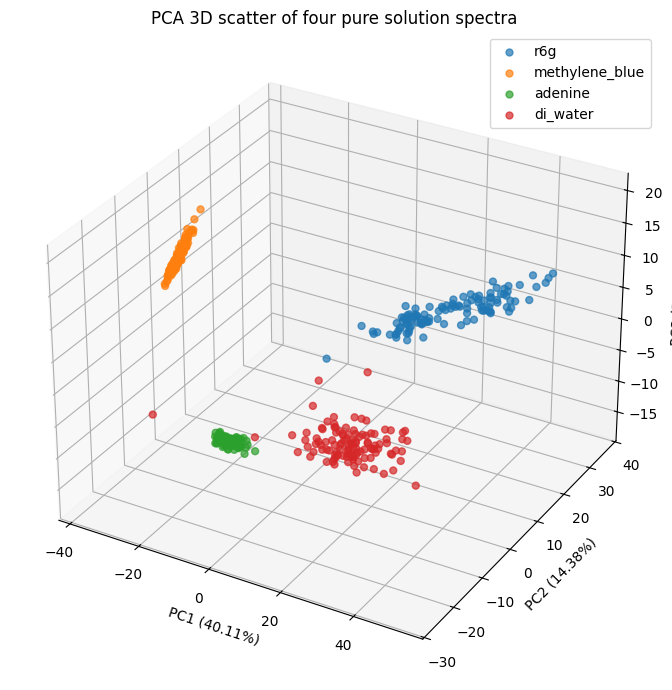


Step 1.5: Generate synthetic mixture spectra from baseline_raw

  Binary combinations (6):
    r6g + methylene_blue: generating 200 synthetic spectra
    r6g + adenine: generating 200 synthetic spectra
    r6g + di_water: generating 200 synthetic spectra
    methylene_blue + adenine: generating 200 synthetic spectra
    methylene_blue + di_water: generating 200 synthetic spectra
    adenine + di_water: generating 200 synthetic spectra

  Extra low-ratio r6g + methylene_blue mixtures:
    r6g=0.01, methylene_blue=0.99: 60
    r6g=0.02, methylene_blue=0.98: 60
    r6g=0.05, methylene_blue=0.95: 60
    r6g=0.10, methylene_blue=0.90: 60
    r6g=0.20, methylene_blue=0.80: 60

  Ternary combinations (4):
    r6g + methylene_blue + adenine: generating 100 synthetic spectra
    r6g + methylene_blue + di_water: generating 100 synthetic spectra
    r6g + adenine + di_water: generating 100 synthetic spectra
    methylene_blue + adenine + di_water: generating 100 synthetic spectra

  Summary:
   

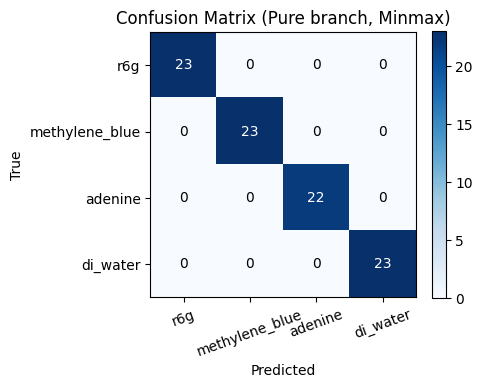


Step 3B: Mixture branch: baseline_raw -> StandardScaler -> PCA + peak features -> OvR SVM
  Mix PCA total explained variance (20 PCs): 57.84%
  Raw pure recon error: mean=33.120, p99=58.097
  Recon threshold (99.0p x 1.5): 87.146
  Mahalanobis: mean=4.254, p99=8.453
  Mahalanobis threshold (ref only): 12.680

  Extracting diagnostic peak features from raw spectra...
  Peak feature dim: 37
  Combined feature dim: 57

  Training 3 target binary classifiers...

  [r6g                 ] pos=930 neg=719
    Best params: {'C': 100, 'gamma': 0.01}
    Test: TP=257 FP=5 FN=3 TN=207
    Precision=0.9809  Recall=0.9885  F1=0.9847

  [methylene_blue      ] pos=949 neg=700
    Best params: {'C': 10, 'gamma': 0.01}
    Test: TP=241 FP=0 FN=1 TN=230
    Precision=1.0000  Recall=0.9959  F1=0.9979

  [adenine             ] pos=697 neg=952
    Best params: {'C': 100, 'gamma': 0.01}
    Test: TP=209 FP=0 FN=0 TN=263
    Precision=1.0000  Recall=1.0000  F1=1.0000

Step 4: Evaluate OvR on synthetic test 

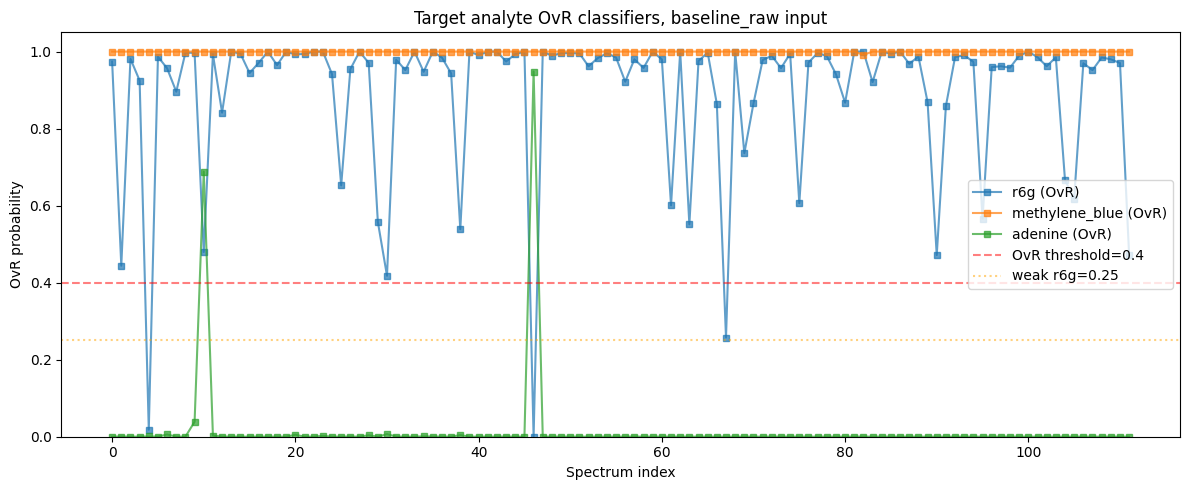

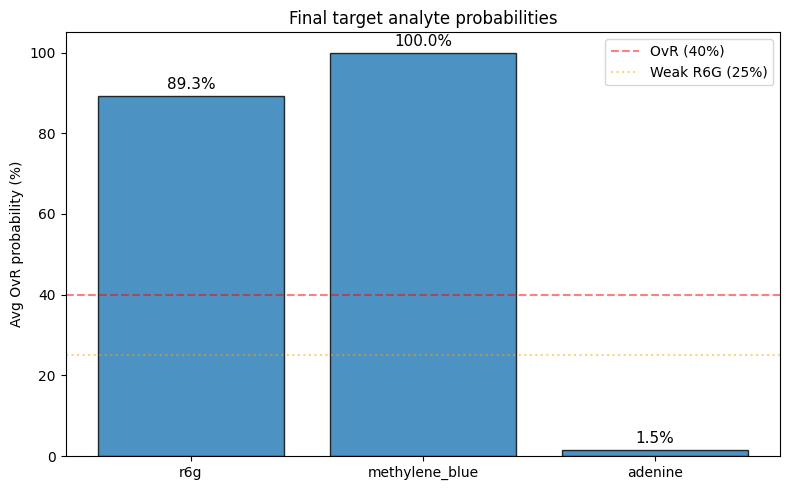

In [6]:
import os
import sys
import re
import json
import csv
import time
import random
from pathlib import Path
from itertools import combinations

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

try:
    from sklearn.decomposition import PCA
    from sklearn.svm import SVC
    from sklearn.preprocessing import StandardScaler
    from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
    from sklearn.model_selection import GridSearchCV
    import joblib
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        "Missing dependency. Please install: pip install scikit-learn joblib matplotlib numpy"
    ) from e


# =========================================================
# CONFIG
# =========================================================
DATA_ROOT = r"/Users/adhar/Downloads/research/Portable_Raman_full_project/laser_test/build/Desktop_Qt_6_6_3_MSVC2019_64bit-Debug"
DATA_DIR = os.path.join(DATA_ROOT, "data_base_code_part")

# ---------------------------------------------------------------------
# Pure multi-class SVM uses MIN-MAX data
# These files are the newly generated *_minmax.npy from your screenshot
# ---------------------------------------------------------------------
TRAINING_MINMAX_NPY_FILES = {
    "r6g": os.path.join(DATA_DIR, "training_spectra_r6g_minmax.npy"),
    "methylene_blue": os.path.join(DATA_DIR, "training_spectra_methylene_blue_minmax.npy"),
    "adenine": os.path.join(DATA_DIR, "training_spectra_adenine_minmax.npy"),
    "di_water": os.path.join(DATA_DIR, "training_spectra_di_water_minmax.npy"),
}

# ---------------------------------------------------------------------
# Mixture OvR SVM uses BASELINE_RAW data
# These files are the newly generated *_baseline_raw.npy from your screenshot
# ---------------------------------------------------------------------
TRAINING_RAW_NPY_FILES = {
    "r6g": os.path.join(DATA_DIR, "training_spectra_r6g_baseline_raw.npy"),
    "methylene_blue": os.path.join(DATA_DIR, "training_spectra_methylene_blue_baseline_raw.npy"),
    "adenine": os.path.join(DATA_DIR, "training_spectra_adenine_baseline_raw.npy"),
    "di_water": os.path.join(DATA_DIR, "training_spectra_di_water_baseline_raw.npy"),
}

TEST_FILE = r"/Users/adhar/Downloads/research/Portable_Raman_full_project/laser_test/build/Desktop_Qt_6_6_3_MSVC2019_64bit-Debug/portable_raman_test_data/laser_log_20260513_150549.txt"
TEST_DARK_FILE = r"/Users/adhar/Downloads/research/Portable_Raman_full_project/laser_test/build/Desktop_Qt_6_6_3_MSVC2019_64bit-Debug/portable_raman_test_data/dark_20260513_150739.txt"

DROP_N = 90
TARGET_LEN = 2048
DO_BASELINE = True
BASELINE_WINDOW = 15
BASELINE_SMOOTH = 15

SEED = 42
TRAIN_RATIO = 0.70
VAL_RATIO = 0.10
TEST_RATIO = 0.20
PCA_PLOT_COMPONENTS = 3

# Each of the two branches has its own PCA
PURE_N_COMPONENTS = 20
MIX_N_COMPONENTS = 20

# ---- Inference thresholds ----
CONFIDENCE_THRESHOLD = 0.80
MIXTURE_THRESHOLD = 0.15

# ---- OvR binary classifier thresholds ----
OVR_THRESHOLD = 0.50
OVR_FINAL_THRESHOLD = 0.40

# If MB clearly dominates but R6G is weakly positive, this threshold can be used to catch weak R6G
R6G_WEAK_THRESHOLD_WHEN_MB_DOMINANT = 0.25

# ---- Synthetic mixture generation from baseline_raw ----
N_SYNTHETIC_PER_COMBO = 200
N_SYNTHETIC_TERNARY = 100
MIXTURE_RATIO_MIN = 0.10
MIXTURE_RATIO_MAX = 0.90

# Noise uses a ratio of the mixture spectrum's own standard deviation, no longer a fixed 0.02
SYNTH_NOISE_STD_RATIO = 0.01

# For r6g + methylene_blue, additionally add synthetic samples with a low r6g ratio
ENABLE_EXTRA_LOW_R6G_MB = True
N_EXTRA_LOW_R6G_MB = 300
LOW_R6G_RATIOS = [0.01, 0.02, 0.05, 0.10, 0.20]

# ---- Quality / recon filters ----
ENABLE_QUALITY_FILTER = True
RAW_MIN_PTP = 100.0
RAW_MIN_STD = 15.0

ENABLE_RECON_FILTER = True
RECON_PERCENTILE = 99.0
RECON_TOLERANCE = 1.5

MAHA_PERCENTILE = 99.0
MAHA_TOLERANCE = 1.5

OUTPUT_DIR = os.path.join(DATA_ROOT, "_PCA_SVM_v7_target_only_pca3")
os.makedirs(OUTPUT_DIR, exist_ok=True)

PURE_SCALER_PATH = os.path.join(OUTPUT_DIR, "pure_scaler_minmax.joblib")
PURE_PCA_PATH = os.path.join(OUTPUT_DIR, "pure_pca_minmax.joblib")
PURE_SVM_PATH = os.path.join(OUTPUT_DIR, "pure_svm_minmax.joblib")

MIX_SCALER_PATH = os.path.join(OUTPUT_DIR, "mix_scaler_raw.joblib")
MIX_PCA_PATH = os.path.join(OUTPUT_DIR, "mix_pca_raw.joblib")
OVR_SCALER_PATH = os.path.join(OUTPUT_DIR, "ovr_scaler_raw.joblib")
OVR_SVMS_PATH = os.path.join(OUTPUT_DIR, "ovr_svms_raw.joblib")

META_PATH = os.path.join(OUTPUT_DIR, "meta.json")


# =========================================================
# DIAGNOSTIC PEAK REGIONS
# =========================================================
DIAGNOSTIC_PEAKS = {
    "r6g": [
        (612, 30),
        (774, 30),
        (1360, 30),
        (1510, 30),
    ],
    "methylene_blue": [
        (450, 30),
        (770, 30),
        (1395, 30),
        (1625, 30),
    ],
    "adenine": [
        (730, 30),
        (1330, 30),
        (1460, 30),
    ],
    "di_water": [],
}


def extract_peak_features(spectrum, cm1_min=200, cm1_max=3200):
    """
    Extract diagnostic peak features from baseline_raw or synthetic raw spectra.
    Note: the input is not required to be min-max here.
    """
    spec = np.asarray(spectrum, dtype=np.float64)
    n = spec.size
    features = []

    for cls_name in ["r6g", "methylene_blue", "adenine"]:
        peaks = DIAGNOSTIC_PEAKS[cls_name]

        for center_cm1, half_w in peaks:
            center_px = int((center_cm1 - cm1_min) / (cm1_max - cm1_min) * n)
            half_px = max(3, int(half_w / (cm1_max - cm1_min) * n))

            lo = max(0, center_px - half_px)
            hi = min(n, center_px + half_px + 1)
            region = spec[lo:hi]

            if region.size == 0:
                features.extend([0.0, 0.0, 0.0])
                continue

            peak_height = float(np.max(region))
            peak_area = float(np.sum(region))

            bg_lo_start = max(0, lo - half_px * 2)
            bg_hi_end = min(n, hi + half_px * 2)
            bg_left = spec[bg_lo_start:lo]
            bg_right = spec[hi:bg_hi_end]

            if bg_left.size + bg_right.size > 0:
                bg_vals = np.concatenate([bg_left, bg_right])
            else:
                bg_vals = np.array([0.0])

            bg_mean = float(np.mean(bg_vals))
            peak_mean = float(np.mean(region))
            peak_contrast = peak_mean - bg_mean

            features.extend([peak_height, peak_area, peak_contrast])

    features.append(float(np.max(spec)))
    features.append(float(np.std(spec)))
    features.append(float(np.sum(spec > 0.3)))
    features.append(float(np.percentile(spec, 95) - np.percentile(spec, 5)))

    return np.array(features, dtype=np.float32)


# =========================================================
# UTILS
# =========================================================
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)


set_seed(SEED)


def _is_jupyter():
    try:
        from IPython import get_ipython
        shell = get_ipython().__class__.__name__
        if shell in ("ZMQInteractiveShell", "TerminalInteractiveShell"):
            return True
    except Exception:
        pass
    return len(sys.argv) > 0 and "jupyter" in sys.argv[0].lower()


def _parse_cli_args():
    if _is_jupyter():
        return TEST_FILE, TEST_DARK_FILE

    args = [a for a in sys.argv[1:] if not a.startswith("-")]
    tf = args[0].strip() if len(args) >= 1 and args[0].strip() else TEST_FILE
    td = args[1].strip() if len(args) >= 2 and args[1].strip() else TEST_DARK_FILE

    return tf, td


def stratified_split_indices_3way(Y, train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO,
                                  test_ratio=TEST_RATIO, seed=SEED):
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6

    rng = random.Random(seed)
    idx_tr, idx_va, idx_te = [], [], []

    for cls in np.unique(Y):
        idx = np.where(Y == cls)[0].tolist()
        rng.shuffle(idx)

        n = len(idx)
        n_tr = max(1, int(round(n * train_ratio)))
        n_va = max(1, int(round(n * val_ratio)))

        if n_tr + n_va >= n:
            n_va = max(1, n - n_tr - 1)

        if n_tr + n_va >= n:
            n_tr = max(1, n - 2)
            n_va = 1

        idx_tr.extend(idx[:n_tr])
        idx_va.extend(idx[n_tr:n_tr + n_va])
        idx_te.extend(idx[n_tr + n_va:])

    rng.shuffle(idx_tr)
    rng.shuffle(idx_va)
    rng.shuffle(idx_te)

    return idx_tr, idx_va, idx_te


ERROR_PHRASE = "image data error code 0x0001"


def strip_prefix(line):
    line = line.strip()
    line = re.sub(r"^\[[^\]]+\]\s+\[Backend\]\s*", "", line)
    line = re.sub(r"^\[[^\]]+\]\s*", "", line)
    return line.strip()


def load_dark_spectrum_from_file(dark_path):
    if not dark_path or not Path(dark_path).exists():
        return np.array([], dtype=np.float64)

    intensities = []

    with open(dark_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()

            if not line or line.startswith("#") or line.startswith("index"):
                continue

            parts = line.split("\t")

            if len(parts) >= 3:
                try:
                    intensities.append(float(parts[2]))
                except ValueError:
                    continue

    return np.array(intensities, dtype=np.float64)


def parse_portable_log_to_spectra(log_file):
    lines = open(log_file, "r", encoding="utf-8", errors="ignore").read().splitlines()

    spectra, failed = [], 0
    i = 0

    while i < len(lines):
        line_raw = lines[i]
        line = strip_prefix(line_raw)

        if ERROR_PHRASE in line_raw.lower():
            failed += 1
            i += 1
            continue

        if line.startswith("Image Data"):
            tokens = list(re.findall(r"\b[0-9A-Fa-f]{2,4}\b", line[len("Image Data"):].strip()))
            j = i + 1
            block_err = False

            while j < len(lines):
                nxt_raw = lines[j]
                nxt = strip_prefix(nxt_raw)

                if ERROR_PHRASE in nxt_raw.lower():
                    block_err = True

                if nxt.startswith("Stop Capture") or (nxt.startswith("Image Data") and j != i):
                    break

                hexes = re.findall(r"\b[0-9A-Fa-f]{2,4}\b", nxt)
                if hexes:
                    tokens.extend(hexes)

                j += 1

            if block_err or not tokens:
                failed += 1
            else:
                vals = np.array([int(t, 16) for t in tokens], dtype=np.int64)

                if vals.size % 2 == 0 and vals.max(initial=0) <= 255:
                    le = vals[0::2] + (vals[1::2] << 8)
                    be = (vals[0::2] << 8) + vals[1::2]
                    v16 = le if le.max(initial=0) >= be.max(initial=0) else be

                    if v16.max(initial=0) > 255:
                        vals = v16.astype(np.int64)

                spectra.append(vals.astype(np.float64))

            i = j + 1
            continue

        i += 1

    return spectra, failed


def moving_average(y, window):
    window = int(max(3, window))
    if window % 2 == 0:
        window += 1

    pad = window // 2
    ypad = np.pad(y, (pad, pad), mode="edge")
    kernel = np.ones(window, dtype=np.float64) / window

    return np.convolve(ypad, kernel, mode="valid")


def rolling_minimum(y, window):
    window = int(max(3, window))
    if window % 2 == 0:
        window += 1

    pad = window // 2
    ypad = np.pad(y, (pad, pad), mode="edge")
    out = np.empty_like(y, dtype=np.float64)

    for i in range(y.size):
        out[i] = np.min(ypad[i:i + window])

    return out


def baseline_correction_fast(y, window=15, smooth=15):
    y = np.asarray(y, dtype=np.float64)

    if y.size < 5:
        return y.copy()

    baseline = rolling_minimum(y, window=window)
    baseline = moving_average(baseline, window=smooth)

    return y - baseline


def normalize_min_max(y):
    y = np.asarray(y, dtype=np.float64)
    ymin, ymax = np.min(y), np.max(y)
    denom = ymax - ymin

    if denom < 1e-12:
        return np.zeros_like(y)

    return (y - ymin) / denom


def preprocess_two_versions(raw_spectrum, dark_raw):
    """
    Return two versions of the same test spectrum:
    baseline_raw: raw-dark -> drop -> baseline correction, no min-max
    minmax:       baseline_raw, then min-max
    """
    s = np.asarray(raw_spectrum, np.float64)

    if s.size < TARGET_LEN:
        return None, None, None

    s2048 = s[:TARGET_LEN]
    d2048 = dark_raw[:TARGET_LEN] if dark_raw.size >= TARGET_LEN else dark_raw

    if d2048.size >= TARGET_LEN:
        raw_dark_full = s2048 - d2048
    else:
        raw_dark_full = s2048.copy()

    if DROP_N >= raw_dark_full.size:
        return None, None, None

    raw_dark = raw_dark_full[DROP_N:]

    quality = {
        "ptp": float(np.ptp(raw_dark)),
        "std": float(np.std(raw_dark)),
    }

    if DO_BASELINE:
        baseline_raw = baseline_correction_fast(
            raw_dark,
            window=BASELINE_WINDOW,
            smooth=BASELINE_SMOOTH,
        )
    else:
        baseline_raw = raw_dark.copy()

    minmax = normalize_min_max(baseline_raw)

    return baseline_raw.astype(np.float32), minmax.astype(np.float32), quality


# =========================================================
# STEP 1: Load MINMAX and RAW pure data
# =========================================================
class_names = list(TRAINING_MINMAX_NPY_FILES.keys())
class_to_id = {c: i for i, c in enumerate(class_names)}
id_to_class = {i: c for c, i in class_to_id.items()}
NUM_CLASSES = len(class_names)

# Final report only uses target analytes.
# di_water is kept in the training data as blank/background control,
# but it is NOT trained or reported as a mixture component.
TARGET_ANALYTES = ["r6g", "methylene_blue", "adenine"]
BACKGROUND_CLASSES = ["di_water"]
TARGET_CIDS = [class_to_id[c] for c in TARGET_ANALYTES]
BACKGROUND_CIDS = [class_to_id[c] for c in BACKGROUND_CLASSES if c in class_to_id]

print("=" * 70)
print("Step 1: Load pure substance data")
print("  pure branch: minmax")
print("  mixture branch: baseline_raw")
print("=" * 70)

pure_data_minmax = {}
pure_data_raw = {}

X_minmax_parts, X_raw_parts, Y_parts = [], [], []

for cls in class_names:
    minmax_path = TRAINING_MINMAX_NPY_FILES[cls]
    raw_path = TRAINING_RAW_NPY_FILES[cls]

    if not os.path.exists(minmax_path):
        raise FileNotFoundError(f"Cannot find the {cls} minmax data file: {minmax_path}")
    if not os.path.exists(raw_path):
        raise FileNotFoundError(f"Cannot find the {cls} baseline_raw data file: {raw_path}")

    data_minmax = np.load(minmax_path).astype(np.float32)
    data_raw = np.load(raw_path).astype(np.float32)

    if data_minmax.shape != data_raw.shape:
        raise ValueError(
            f"{cls} minmax and raw shape mismatch: minmax={data_minmax.shape}, raw={data_raw.shape}"
        )

    pure_data_minmax[cls] = data_minmax
    pure_data_raw[cls] = data_raw

    print(f"  {cls:20s}  minmax={data_minmax.shape}  raw={data_raw.shape}")

    X_minmax_parts.append(data_minmax)
    X_raw_parts.append(data_raw)
    Y_parts.append(np.full(data_minmax.shape[0], class_to_id[cls], dtype=np.int64))

X_pure_minmax = np.vstack(X_minmax_parts).astype(np.float32)
X_pure_raw = np.vstack(X_raw_parts).astype(np.float32)
Y_pure = np.concatenate(Y_parts)

FEATURE_DIM = X_pure_minmax.shape[1]

print(f"\nPure minmax total: {X_pure_minmax.shape}")
print(f"Pure raw total:    {X_pure_raw.shape}")
print(f"Feature dimension: {FEATURE_DIM}")




# =========================================================
# STEP 1.2: PCA 3D visualization of four pure solutions
# =========================================================
print("\n" + "=" * 70)
print("Step 1.2: PCA 3D visualization of four pure solutions")
print("  input: minmax pure spectra")
print("=" * 70)

# This PCA plot is only for visualization.
# It does not replace the pure branch PCA or mixture branch PCA used later.
pca3_scaler = StandardScaler()
X_pure_minmax_scaled_for_plot = pca3_scaler.fit_transform(X_pure_minmax)

pca3 = PCA(n_components=3, random_state=SEED)
X_pure_pca3 = pca3.fit_transform(X_pure_minmax_scaled_for_plot)
explained3 = pca3.explained_variance_ratio_

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
plot_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]

for cid in range(NUM_CLASSES):
    mask = Y_pure == cid
    ax.scatter(
        X_pure_pca3[mask, 0],
        X_pure_pca3[mask, 1],
        X_pure_pca3[mask, 2],
        label=id_to_class[cid],
        alpha=0.70,
        s=25,
        color=plot_colors[cid % len(plot_colors)],
    )

ax.set_xlabel(f"PC1 ({explained3[0] * 100:.2f}%)")
ax.set_ylabel(f"PC2 ({explained3[1] * 100:.2f}%)")
ax.set_zlabel(f"PC3 ({explained3[2] * 100:.2f}%)")
ax.set_title("PCA 3D scatter of four pure solution spectra")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

# =========================================================
# STEP 1.5: Generate synthetic mixture spectra from RAW data
# =========================================================
print("\n" + "=" * 70)
print("Step 1.5: Generate synthetic mixture spectra from baseline_raw")
print("=" * 70)

rng_mix = np.random.RandomState(SEED)

X_mix_raw_list = [X_pure_raw.copy()]
Y_ml_list = []

for i in range(X_pure_raw.shape[0]):
    label = np.zeros(NUM_CLASSES, dtype=np.float32)
    label[Y_pure[i]] = 1.0
    Y_ml_list.append(label)

n_pure = X_pure_raw.shape[0]

# Binary mixtures
binary_combos = list(combinations(range(NUM_CLASSES), 2))
print(f"\n  Binary combinations ({len(binary_combos)}):")
n_binary = 0

for cid_a, cid_b in binary_combos:
    cls_a, cls_b = id_to_class[cid_a], id_to_class[cid_b]
    data_a, data_b = pure_data_raw[cls_a], pure_data_raw[cls_b]

    print(f"    {cls_a} + {cls_b}: generating {N_SYNTHETIC_PER_COMBO} synthetic spectra")

    for _ in range(N_SYNTHETIC_PER_COMBO):
        spec_a = data_a[rng_mix.randint(0, len(data_a))]
        spec_b = data_b[rng_mix.randint(0, len(data_b))]

        ratio_a = rng_mix.uniform(MIXTURE_RATIO_MIN, MIXTURE_RATIO_MAX)
        ratio_b = 1.0 - ratio_a

        # Key change: mix in the baseline_raw intensity space, no longer mixing minmax pure spectra
        mix_raw = ratio_a * spec_a + ratio_b * spec_b

        if SYNTH_NOISE_STD_RATIO > 0:
            noise_std = SYNTH_NOISE_STD_RATIO * max(float(np.std(mix_raw)), 1e-6)
            noise = rng_mix.normal(0, noise_std, size=mix_raw.shape).astype(np.float32)
            mix_raw = mix_raw + noise

        X_mix_raw_list.append(mix_raw.reshape(1, -1))

        label = np.zeros(NUM_CLASSES, dtype=np.float32)
        label[cid_a] = 1.0
        label[cid_b] = 1.0
        Y_ml_list.append(label)

        n_binary += 1

# Additionally reinforce the r6g + methylene_blue low-ratio scenario
if ENABLE_EXTRA_LOW_R6G_MB and "r6g" in class_to_id and "methylene_blue" in class_to_id:
    cid_r6g = class_to_id["r6g"]
    cid_mb = class_to_id["methylene_blue"]

    data_r6g = pure_data_raw["r6g"]
    data_mb = pure_data_raw["methylene_blue"]

    print("\n  Extra low-ratio r6g + methylene_blue mixtures:")

    per_ratio = max(1, N_EXTRA_LOW_R6G_MB // len(LOW_R6G_RATIOS))

    for ratio_r6g in LOW_R6G_RATIOS:
        print(f"    r6g={ratio_r6g:.2f}, methylene_blue={1-ratio_r6g:.2f}: {per_ratio}")

        for _ in range(per_ratio):
            spec_r6g = data_r6g[rng_mix.randint(0, len(data_r6g))]
            spec_mb = data_mb[rng_mix.randint(0, len(data_mb))]

            mix_raw = ratio_r6g * spec_r6g + (1.0 - ratio_r6g) * spec_mb

            if SYNTH_NOISE_STD_RATIO > 0:
                noise_std = SYNTH_NOISE_STD_RATIO * max(float(np.std(mix_raw)), 1e-6)
                noise = rng_mix.normal(0, noise_std, size=mix_raw.shape).astype(np.float32)
                mix_raw = mix_raw + noise

            X_mix_raw_list.append(mix_raw.reshape(1, -1))

            label = np.zeros(NUM_CLASSES, dtype=np.float32)
            label[cid_r6g] = 1.0
            label[cid_mb] = 1.0
            Y_ml_list.append(label)

            n_binary += 1

# Ternary mixtures
ternary_combos = list(combinations(range(NUM_CLASSES), 3))
n_ternary = 0

if N_SYNTHETIC_TERNARY > 0:
    print(f"\n  Ternary combinations ({len(ternary_combos)}):")

    for combo in ternary_combos:
        names = [id_to_class[c] for c in combo]
        print(f"    {' + '.join(names)}: generating {N_SYNTHETIC_TERNARY} synthetic spectra")

        for _ in range(N_SYNTHETIC_TERNARY):
            specs = [
                pure_data_raw[id_to_class[c]][rng_mix.randint(0, len(pure_data_raw[id_to_class[c]]))]
                for c in combo
            ]

            while True:
                ratios = rng_mix.dirichlet([1.0] * len(combo))
                if all(r >= MIXTURE_RATIO_MIN for r in ratios):
                    break

            mix_raw = sum(r * s for r, s in zip(ratios, specs))

            if SYNTH_NOISE_STD_RATIO > 0:
                noise_std = SYNTH_NOISE_STD_RATIO * max(float(np.std(mix_raw)), 1e-6)
                noise = rng_mix.normal(0, noise_std, size=mix_raw.shape).astype(np.float32)
                mix_raw = mix_raw + noise

            X_mix_raw_list.append(mix_raw.reshape(1, -1))

            label = np.zeros(NUM_CLASSES, dtype=np.float32)
            for c in combo:
                label[c] = 1.0
            Y_ml_list.append(label)

            n_ternary += 1

X_mix_raw_all = np.vstack(X_mix_raw_list).astype(np.float32)
Y_ml = np.stack(Y_ml_list).astype(np.float32)

print("\n  Summary:")
print(f"    Pure raw spectra: {n_pure}")
print(f"    Binary synthetic: {n_binary}")
print(f"    Ternary synthetic:{n_ternary}")
print(f"    Total raw mix set:{X_mix_raw_all.shape[0]}")
print(f"    X_mix_raw_all shape: {X_mix_raw_all.shape},  Y_ml shape: {Y_ml.shape}")


# =========================================================
# STEP 2: Split
# =========================================================
print("\n" + "=" * 70)
print("Step 2: Train/Val/Test split")
print("=" * 70)

# pure branch split
idx_tr_pure, idx_va_pure, idx_te_pure = stratified_split_indices_3way(Y_pure)

X_train_pure_minmax = X_pure_minmax[idx_tr_pure]
Y_train_pure_cls = Y_pure[idx_tr_pure]
X_test_pure_minmax = X_pure_minmax[idx_te_pure]
Y_test_pure_cls = Y_pure[idx_te_pure]

# mixture branch split
all_mix_indices = list(range(X_mix_raw_all.shape[0]))
rng_split = random.Random(SEED)
rng_split.shuffle(all_mix_indices)

n_all_mix = len(all_mix_indices)
n_mix_tr = int(n_all_mix * TRAIN_RATIO)
n_mix_va = int(n_all_mix * VAL_RATIO)

idx_tr_mix = all_mix_indices[:n_mix_tr]
idx_va_mix = all_mix_indices[n_mix_tr:n_mix_tr + n_mix_va]
idx_te_mix = all_mix_indices[n_mix_tr + n_mix_va:]

X_train_mix_raw = X_mix_raw_all[idx_tr_mix]
Y_ml_train = Y_ml[idx_tr_mix]
X_test_mix_raw = X_mix_raw_all[idx_te_mix]
Y_ml_test = Y_ml[idx_te_mix]

print(f"  Pure branch: train={len(idx_tr_pure)} test={len(idx_te_pure)}")
print(f"  Mix branch:  train={len(idx_tr_mix)} val={len(idx_va_mix)} test={len(idx_te_mix)}")

for cid in range(NUM_CLASSES):
    n_tr_pos = int(Y_ml_train[:, cid].sum())
    n_te_pos = int(Y_ml_test[:, cid].sum())
    print(f"    {id_to_class[cid]:20s}  mix_train_positive={n_tr_pos}  mix_test_positive={n_te_pos}")


# =========================================================
# STEP 3A: Pure branch scaler + PCA + multi-class SVM
# =========================================================
print("\n" + "=" * 70)
print("Step 3A: Pure branch: minmax -> StandardScaler -> PCA -> Multi-class SVM")
print("=" * 70)

pure_scaler = StandardScaler()
X_train_pure_scaled = pure_scaler.fit_transform(X_train_pure_minmax)
X_test_pure_scaled = pure_scaler.transform(X_test_pure_minmax)

pure_pca = PCA(n_components=PURE_N_COMPONENTS, random_state=SEED)
X_train_pure_pca = pure_pca.fit_transform(X_train_pure_scaled)
X_test_pure_pca = pure_pca.transform(X_test_pure_scaled)

pure_cumulative = np.cumsum(pure_pca.explained_variance_ratio_)
print(f"  Pure PCA total explained variance ({PURE_N_COMPONENTS} PCs): {pure_cumulative[-1]*100:.2f}%")

param_grid = {"C": [0.1, 1, 10, 100], "gamma": ["scale", "auto", 0.01, 0.1, 1]}
svm_base = SVC(kernel="rbf", probability=True, random_state=SEED)
grid = GridSearchCV(svm_base, param_grid, cv=5, scoring="accuracy", n_jobs=1, verbose=0)
grid.fit(X_train_pure_pca, Y_train_pure_cls)

svm = grid.best_estimator_

Y_pred_test_pure = svm.predict(X_test_pure_pca)
test_acc = accuracy_score(Y_test_pure_cls, Y_pred_test_pure)
train_acc = accuracy_score(Y_train_pure_cls, svm.predict(X_train_pure_pca))

print(f"  Best params: {grid.best_params_}")
print(f"  Pure train accuracy: {train_acc:.4f}")
print(f"  Pure test accuracy:  {test_acc:.4f}")
print("\nClassification report (pure branch, minmax):")
print(classification_report(Y_test_pure_cls, Y_pred_test_pure, target_names=class_names, digits=4))

cm = confusion_matrix(Y_test_pure_cls, Y_pred_test_pure)
plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Confusion Matrix (Pure branch, Minmax)")
plt.colorbar()
tick_marks = np.arange(NUM_CLASSES)
plt.xticks(tick_marks, class_names, rotation=20)
plt.yticks(tick_marks, class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )
plt.tight_layout()
plt.show()


# =========================================================
# STEP 3B: Mix branch scaler + PCA + OvR
# =========================================================
print("\n" + "=" * 70)
print("Step 3B: Mixture branch: baseline_raw -> StandardScaler -> PCA + peak features -> OvR SVM")
print("=" * 70)

mix_scaler = StandardScaler()
X_train_mix_scaled = mix_scaler.fit_transform(X_train_mix_raw)
X_test_mix_scaled = mix_scaler.transform(X_test_mix_raw)

mix_pca = PCA(n_components=MIX_N_COMPONENTS, random_state=SEED)
X_train_mix_pca = mix_pca.fit_transform(X_train_mix_scaled)
X_test_mix_pca = mix_pca.transform(X_test_mix_scaled)

mix_cumulative = np.cumsum(mix_pca.explained_variance_ratio_)
print(f"  Mix PCA total explained variance ({MIX_N_COMPONENTS} PCs): {mix_cumulative[-1]*100:.2f}%")

# reconstruction threshold from raw pure training only
X_train_raw_pure_for_recon = X_pure_raw[idx_tr_pure]
X_train_raw_pure_scaled = mix_scaler.transform(X_train_raw_pure_for_recon)
X_train_raw_pure_pca = mix_pca.transform(X_train_raw_pure_scaled)
X_train_raw_pure_recon = mix_pca.inverse_transform(X_train_raw_pure_pca)
train_recon_errors = np.linalg.norm(X_train_raw_pure_scaled - X_train_raw_pure_recon, axis=1)
recon_threshold = float(np.percentile(train_recon_errors, RECON_PERCENTILE) * RECON_TOLERANCE)

print(f"  Raw pure recon error: mean={train_recon_errors.mean():.3f}, p99={np.percentile(train_recon_errors, 99):.3f}")
print(f"  Recon threshold ({RECON_PERCENTILE}p x {RECON_TOLERANCE}): {recon_threshold:.3f}")

class_centroids, class_cov_inv = {}, {}
for cid in range(NUM_CLASSES):
    raw_cls = X_pure_raw[Y_pure == cid]
    raw_cls_scaled = mix_scaler.transform(raw_cls)
    raw_cls_pca = mix_pca.transform(raw_cls_scaled)
    centroid = raw_cls_pca.mean(axis=0)
    cov = np.cov(raw_cls_pca.T) + np.eye(MIX_N_COMPONENTS) * 1e-4
    class_centroids[cid] = centroid
    class_cov_inv[cid] = np.linalg.inv(cov)


def mahalanobis_to_nearest(pt_pca):
    dists = []
    for cid in range(NUM_CLASSES):
        diff = pt_pca - class_centroids[cid]
        d = float(np.sqrt(diff @ class_cov_inv[cid] @ diff))
        dists.append(d)
    return min(dists), dists


train_maha_dists = np.array([mahalanobis_to_nearest(X_train_raw_pure_pca[i])[0]
                              for i in range(X_train_raw_pure_pca.shape[0])])
maha_threshold = float(np.percentile(train_maha_dists, MAHA_PERCENTILE) * MAHA_TOLERANCE)
print(f"  Mahalanobis: mean={train_maha_dists.mean():.3f}, p99={np.percentile(train_maha_dists, 99):.3f}")
print(f"  Mahalanobis threshold (ref only): {maha_threshold:.3f}")

print("\n  Extracting diagnostic peak features from raw spectra...")
X_peak_train = np.array([extract_peak_features(X_train_mix_raw[i]) for i in range(X_train_mix_raw.shape[0])], dtype=np.float32)
X_peak_test = np.array([extract_peak_features(X_test_mix_raw[i]) for i in range(X_test_mix_raw.shape[0])], dtype=np.float32)
PEAK_FEAT_DIM = X_peak_train.shape[1]

X_ovr_train = np.hstack([X_train_mix_pca, X_peak_train])
X_ovr_test = np.hstack([X_test_mix_pca, X_peak_test])

ovr_scaler = StandardScaler()
X_ovr_train_scaled = ovr_scaler.fit_transform(X_ovr_train)
X_ovr_test_scaled = ovr_scaler.transform(X_ovr_test)

print(f"  Peak feature dim: {PEAK_FEAT_DIM}")
print(f"  Combined feature dim: {X_ovr_train.shape[1]}")

ovr_svms = {}
ovr_param_grid = {"C": [0.1, 1, 10, 100], "gamma": ["scale", "auto", 0.01, 0.1]}

print(f"\n  Training {len(TARGET_CIDS)} target binary classifiers...")
for cid in TARGET_CIDS:
    cls_name = id_to_class[cid]

    Y_bin_train = Y_ml_train[:, cid].astype(np.int64)
    Y_bin_test = Y_ml_test[:, cid].astype(np.int64)

    n_pos = int(Y_bin_train.sum())
    n_neg = int((1 - Y_bin_train).sum())

    svm_bin = SVC(kernel="rbf", probability=True, random_state=SEED, class_weight="balanced")
    grid_bin = GridSearchCV(svm_bin, ovr_param_grid, cv=5, scoring="f1", n_jobs=1, verbose=0)
    grid_bin.fit(X_ovr_train_scaled, Y_bin_train)

    best_svm = grid_bin.best_estimator_
    ovr_svms[cid] = best_svm

    Y_bin_pred = best_svm.predict(X_ovr_test_scaled)

    tp = int(((Y_bin_pred == 1) & (Y_bin_test == 1)).sum())
    fp = int(((Y_bin_pred == 1) & (Y_bin_test == 0)).sum())
    fn = int(((Y_bin_pred == 0) & (Y_bin_test == 1)).sum())
    tn = int(((Y_bin_pred == 0) & (Y_bin_test == 0)).sum())

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    print(f"\n  [{cls_name:20s}] pos={n_pos} neg={n_neg}")
    print(f"    Best params: {grid_bin.best_params_}")
    print(f"    Test: TP={tp} FP={fp} FN={fn} TN={tn}")
    print(f"    Precision={precision:.4f}  Recall={recall:.4f}  F1={f1:.4f}")


# =========================================================
# STEP 4: Evaluate OvR on synthetic test mixtures
# =========================================================
print("\n" + "=" * 70)
print("Step 4: Evaluate OvR on synthetic test mixtures")
print("=" * 70)

# Figure 4 benchmark uses a fixed 0.50 threshold.  The 0.40/0.25 rules below
# are reserved for sample-level real-scan reporting.
BENCHMARK_THRESHOLD = 0.50
target_names = [id_to_class[cid] for cid in TARGET_CIDS]
y_true_target = Y_ml_test[:, TARGET_CIDS].astype(np.int64)
y_prob_target = np.column_stack([
    ovr_svms[cid].predict_proba(X_ovr_test_scaled)[:, 1] for cid in TARGET_CIDS
]).astype(np.float64)
y_pred_target = (y_prob_target >= BENCHMARK_THRESHOLD).astype(np.int64)

target_label_counts = y_true_target.sum(axis=1)
multi_label_mask = target_label_counts > 1
n_mix_test = int(multi_label_mask.sum())
target_exact = float(np.mean(np.all(y_pred_target == y_true_target, axis=1)))
mixture_exact = (
    float(np.mean(np.all(y_pred_target[multi_label_mask] == y_true_target[multi_label_mask], axis=1)))
    if n_mix_test else float("nan")
)

per_target_rows = []
for j, name in enumerate(target_names):
    yt = y_true_target[:, j]
    yp = y_pred_target[:, j]
    pr = y_prob_target[:, j]
    tp = int(((yp == 1) & (yt == 1)).sum())
    fp = int(((yp == 1) & (yt == 0)).sum())
    fn = int(((yp == 0) & (yt == 1)).sum())
    tn = int(((yp == 0) & (yt == 0)).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    auc = float(roc_auc_score(yt, pr)) if np.unique(yt).size == 2 else float("nan")
    per_target_rows.append({
        "model": "PCA-SVM", "target": name,
        "precision": precision, "recall": recall, "f1": f1, "roc_auc": auc,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "positive_support": int(yt.sum()), "n_test": int(len(yt)),
        "benchmark_threshold": BENCHMARK_THRESHOLD,
    })

target_macro_f1 = float(np.mean([row["f1"] for row in per_target_rows]))
target_macro_roc_auc = float(np.mean([row["roc_auc"] for row in per_target_rows]))
r6g_recall = next(row["recall"] for row in per_target_rows if row["target"] == "r6g")
overall_row = {
    "model": "PCA-SVM", "n_test": int(len(y_true_target)), "n_mixture": n_mix_test,
    "target_macro_f1": target_macro_f1,
    "target_macro_roc_auc": target_macro_roc_auc,
    "r6g_recall": r6g_recall, "mixture_exact_match": mixture_exact,
    "target_exact_match": target_exact, "all_label_exact_match": "",
    "benchmark_threshold": BENCHMARK_THRESHOLD,
}

FIG4_OVERALL_PATH = os.path.join(OUTPUT_DIR, "figure4_overall_metrics.csv")
FIG4_PER_TARGET_PATH = os.path.join(OUTPUT_DIR, "figure4_per_target_metrics.csv")
FIG4_PREDICTIONS_PATH = os.path.join(OUTPUT_DIR, "figure4_test_predictions.npz")
with open(FIG4_OVERALL_PATH, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(overall_row.keys()))
    writer.writeheader(); writer.writerow(overall_row)
with open(FIG4_PER_TARGET_PATH, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(per_target_rows[0].keys()))
    writer.writeheader(); writer.writerows(per_target_rows)
np.savez_compressed(
    FIG4_PREDICTIONS_PATH, test_indices=np.asarray(idx_te_mix), target_names=np.asarray(target_names),
    y_true=y_true_target, y_prob=y_prob_target, y_pred=y_pred_target,
)

print(f"  Multi-target mixture samples: {n_mix_test}")
print(f"  Mixture exact match: {mixture_exact:.2%}")
print(f"  Target macro-F1: {target_macro_f1:.4f}")
print(f"  Target macro ROC-AUC: {target_macro_roc_auc:.4f}")
print(f"  Saved Figure 4 metrics: {FIG4_OVERALL_PATH}")


# =========================================================
# STEP 5: Save models
# =========================================================
print("\n" + "=" * 70)
print("Step 5: Save models")
print("=" * 70)

joblib.dump(pure_scaler, PURE_SCALER_PATH)
joblib.dump(pure_pca, PURE_PCA_PATH)
joblib.dump(svm, PURE_SVM_PATH)

joblib.dump(mix_scaler, MIX_SCALER_PATH)
joblib.dump(mix_pca, MIX_PCA_PATH)
joblib.dump(ovr_scaler, OVR_SCALER_PATH)
joblib.dump(ovr_svms, OVR_SVMS_PATH)

meta = {
    "classes": class_names,
    "feature_dim": int(FEATURE_DIM),
    "pure_branch": {
        "input": "minmax",
        "n_components": PURE_N_COMPONENTS,
        "explained_variance_total": float(pure_cumulative[-1]),
        "best_C": grid.best_params_["C"],
        "best_gamma": str(grid.best_params_["gamma"]),
        "test_accuracy_pure": float(test_acc),
        "confidence_threshold": CONFIDENCE_THRESHOLD,
    },
    "mix_branch": {
        "input": "baseline_raw",
        "n_components": MIX_N_COMPONENTS,
        "explained_variance_total": float(mix_cumulative[-1]),
        "peak_feature_dim": int(PEAK_FEAT_DIM),
        "ovr_threshold": OVR_THRESHOLD,
        "ovr_final_threshold": OVR_FINAL_THRESHOLD,
        "r6g_weak_threshold_when_mb_dominant": R6G_WEAK_THRESHOLD_WHEN_MB_DOMINANT,
        "recon_threshold": float(recon_threshold),
        "maha_threshold": float(maha_threshold),
        "n_synthetic_binary": int(n_binary),
        "n_synthetic_ternary": int(n_ternary),
    },
    "split": {"train": TRAIN_RATIO, "val": VAL_RATIO, "test": TEST_RATIO},
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
}

with open(META_PATH, "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

print(f"  Saved all models to: {OUTPUT_DIR}")


# =========================================================
# STEP 6: Inference on real test file
# =========================================================
print("\n" + "=" * 70)
print("Step 6: Inference on real test file")
print("=" * 70)

RUNTIME_TEST_FILE, RUNTIME_TEST_DARK = _parse_cli_args()

print(f"  Test file: {RUNTIME_TEST_FILE}")
print(f"  Dark file: {RUNTIME_TEST_DARK}")

pure_scaler2 = joblib.load(PURE_SCALER_PATH)
pure_pca2 = joblib.load(PURE_PCA_PATH)
svm2 = joblib.load(PURE_SVM_PATH)

mix_scaler2 = joblib.load(MIX_SCALER_PATH)
mix_pca2 = joblib.load(MIX_PCA_PATH)
ovr_scaler2 = joblib.load(OVR_SCALER_PATH)
ovr_svms2 = joblib.load(OVR_SVMS_PATH)

dark_raw = load_dark_spectrum_from_file(RUNTIME_TEST_DARK)
spectra, failed = parse_portable_log_to_spectra(RUNTIME_TEST_FILE)

print(f"\n  Parsed: {len(spectra)} spectra, {failed} failed")

per_block = []
rejected_blocks = []

for idx, raw in enumerate(spectra):
    v_raw, v_minmax, quality = preprocess_two_versions(raw, dark_raw)

    if v_raw is None or v_minmax is None or np.allclose(v_raw, 0):
        rejected_blocks.append({"idx": idx, "reason": "preprocessing failed"})
        continue

    if ENABLE_QUALITY_FILTER:
        if quality["ptp"] < RAW_MIN_PTP or quality["std"] < RAW_MIN_STD:
            rejected_blocks.append({"idx": idx, "reason": f"low signal (ptp={quality['ptp']:.1f})"})
            continue

    # -------------------------
    # Pure branch: minmax
    # -------------------------
    v_minmax_scaled = pure_scaler2.transform(v_minmax.reshape(1, -1))
    v_pure_pca = pure_pca2.transform(v_minmax_scaled)

    prob = svm2.predict_proba(v_pure_pca)[0]
    pred = int(np.argmax(prob))
    conf = float(prob[pred])

    # -------------------------
    # Mixture branch: raw
    # -------------------------
    v_raw_scaled = mix_scaler2.transform(v_raw.reshape(1, -1))
    v_mix_pca = mix_pca2.transform(v_raw_scaled)

    recon_err = None
    if ENABLE_RECON_FILTER:
        v_recon = mix_pca2.inverse_transform(v_mix_pca)
        recon_err = float(np.linalg.norm(v_raw_scaled - v_recon))
        if recon_err > recon_threshold:
            rejected_blocks.append({"idx": idx, "reason": f"high recon error ({recon_err:.2f})"})
            continue

    maha_min, _ = mahalanobis_to_nearest(v_mix_pca[0])

    peak_feat = extract_peak_features(v_raw).reshape(1, -1)
    v_ovr = np.hstack([v_mix_pca, peak_feat])
    v_ovr_scaled = ovr_scaler2.transform(v_ovr)

    ovr_probs = {}
    for cid in TARGET_CIDS:
        p = float(ovr_svms2[cid].predict_proba(v_ovr_scaled)[:, 1][0])
        ovr_probs[cid] = p

    per_block.append({
        "idx": idx,
        "prob": prob,
        "pred": pred,
        "conf": conf,
        "ovr_probs": ovr_probs,
        "recon_err": recon_err,
        "maha": maha_min,
        "quality": quality,
    })

    mc_str = "  ".join(f"{id_to_class[k]}={prob[k]:.3f}" for k in range(NUM_CLASSES))
    ovr_str = "  ".join(f"{id_to_class[k]}={ovr_probs[k]:.3f}" for k in TARGET_CIDS)

    print(f"  [SPEC {idx:3d}]")
    print(f"    PURE/minmax: {id_to_class[pred]:15s} conf={conf:.3f}  [{mc_str}]")
    print(f"    MIX/raw OvR: [{ovr_str}]")


# =========================================================
# FINAL DECISION
# =========================================================
print("\n" + "=" * 70)
print("FINAL DECISION (Fused: Pure minmax + Mix raw OvR)")
print("=" * 70)

n_accepted = len(per_block)
n_rejected = len(rejected_blocks)

print(f"  Total spectra: {len(spectra)}, parse-failed: {failed}")
print(f"  Accepted: {n_accepted}  |  Rejected: {n_rejected}")

if rejected_blocks:
    reason_counts = {}
    for r in rejected_blocks:
        key = r["reason"].split("(")[0].strip()
        reason_counts[key] = reason_counts.get(key, 0) + 1

    print("  Rejection reasons:")
    for k, v in reason_counts.items():
        print(f"    {k}: {v}")

if n_accepted == 0:
    print("\n  >>> RESULT: UNKNOWN")
    print("  >>> Reason: no spectra passed filters")
else:
    avg_prob = np.mean(np.stack([b["prob"] for b in per_block]), axis=0)
    avg_pred = int(np.argmax(avg_prob))
    avg_conf = float(avg_prob[avg_pred])

    avg_ovr = {}
    for cid in TARGET_CIDS:
        avg_ovr[cid] = float(np.mean([b["ovr_probs"][cid] for b in per_block]))

    print(f"\n  === Pure branch summary, minmax input (not used for final component reporting) ===")
    print(f"    dominant_pattern = {id_to_class[avg_pred]}  prob={avg_conf:.4f}")

    print(f"\n  === Target analyte OvR, baseline_raw input ===")
    for k in TARGET_CIDS:
        marker = " ***" if avg_ovr[k] >= OVR_FINAL_THRESHOLD else ""
        print(f"    {id_to_class[k]:20s}  {avg_ovr[k]:.4f}{marker}")

    if BACKGROUND_CIDS:
        print(f"\n  === Background classes ignored in final report ===")
        for k in BACKGROUND_CIDS:
            print(f"    {id_to_class[k]:20s}  ignored as solvent/background")

    # Final detected components: only target analytes are reportable.
    detected = set()
    for cid in TARGET_CIDS:
        if avg_ovr[cid] >= OVR_FINAL_THRESHOLD:
            detected.add(cid)

    # Weak R6G rule:
    # If methylene_blue is detected and r6g crosses the weaker threshold,
    # report r6g as a weak co-component.
    if (
        class_to_id["methylene_blue"] in detected
        and avg_ovr[class_to_id["r6g"]] >= R6G_WEAK_THRESHOLD_WHEN_MB_DOMINANT
    ):
        detected.add(class_to_id["r6g"])

    print(f"\n  Target OvR detected: {[id_to_class[c] for c in sorted(detected)]}")

    if len(detected) == 0:
        print("\n  >>> RESULT: UNKNOWN")
        print("  >>> No target analyte crossed the OvR threshold.")

    elif len(detected) == 1:
        cid = list(detected)[0]
        label = id_to_class[cid]
        print(f"\n  >>> RESULT: {label}")
        print(f"  >>> OvR probability: {avg_ovr[cid]:.4f}")

    else:
        components = []
        for cid in sorted(detected):
            components.append((id_to_class[cid], avg_ovr[cid]))

        components.sort(key=lambda x: x[1], reverse=True)
        comp_names = [c[0] for c in components]

        print(f"\n  >>> RESULT: MIXTURE  ->  {' + '.join(comp_names)}")
        print("  >>> Detected target components:")
        for name, ovr_p in components:
            weak_note = ""
            if name == "r6g" and ovr_p < OVR_FINAL_THRESHOLD:
                weak_note = "  weak-positive"
            print(f"      {name:20s}  OvR={ovr_p:.4f}{weak_note}")

print("=" * 70)


# =========================================================
# PLOTS
# =========================================================
if per_block:
    avg_ovr_final = {
        cid: float(np.mean([b["ovr_probs"][cid] for b in per_block]))
        for cid in TARGET_CIDS
    }
    xs = [b["idx"] for b in per_block]

    # Plot 1: Per-block target OvR only
    plt.figure(figsize=(12, 5))
    for cid in TARGET_CIDS:
        probs = [b["ovr_probs"][cid] for b in per_block]
        plt.plot(xs, probs, marker="s", markersize=4, label=f"{id_to_class[cid]} (OvR)", alpha=0.7)

    plt.axhline(
        y=OVR_FINAL_THRESHOLD,
        color="red",
        linestyle="--",
        alpha=0.5,
        label=f"OvR threshold={OVR_FINAL_THRESHOLD}",
    )
    plt.axhline(
        y=R6G_WEAK_THRESHOLD_WHEN_MB_DOMINANT,
        color="orange",
        linestyle=":",
        alpha=0.5,
        label=f"weak r6g={R6G_WEAK_THRESHOLD_WHEN_MB_DOMINANT}",
    )
    plt.xlabel("Spectrum index")
    plt.ylabel("OvR probability")
    plt.title("Target analyte OvR classifiers, baseline_raw input")
    plt.legend(loc="center right")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

    # Plot 2: Average target OvR probabilities
    plt.figure(figsize=(8, 5))
    target_names = [id_to_class[cid] for cid in TARGET_CIDS]
    ovr_vals = [avg_ovr_final[cid] for cid in TARGET_CIDS]

    bars = plt.bar(
        target_names,
        [v * 100 for v in ovr_vals],
        alpha=0.8,
        edgecolor="black",
    )

    plt.axhline(
        y=OVR_FINAL_THRESHOLD * 100,
        color="red",
        linestyle="--",
        alpha=0.5,
        label=f"OvR ({OVR_FINAL_THRESHOLD*100:.0f}%)",
    )
    plt.axhline(
        y=R6G_WEAK_THRESHOLD_WHEN_MB_DOMINANT * 100,
        color="orange",
        linestyle=":",
        alpha=0.5,
        label=f"Weak R6G ({R6G_WEAK_THRESHOLD_WHEN_MB_DOMINANT*100:.0f}%)",
    )

    plt.ylabel("Avg OvR probability (%)")
    plt.title("Final target analyte probabilities")
    plt.ylim(0, 105)
    plt.legend()

    for bar, val in zip(bars, ovr_vals):
        if val > 0.01:
            plt.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 1,
                f"{val*100:.1f}%",
                ha="center",
                va="bottom",
                fontsize=11,
            )

    plt.tight_layout()
    plt.show()
